# Merchant ranking — baseline (no fraud)

Takes the merchant feature table from `01_data_quality_eda.ipynb`, adds the two things it does not
cover, and turns the result into a ranked top 100. **Run that notebook first.**

| From `01_data_quality_eda` | Added here |
| --- | --- |
| Commercial value, customer reach, engagement, growth, history, stability | Customer concentration (HHI of revenue across customers) |
| | Customer base from `consumers_sa2` — income, IRSAD, geographic spread |
| | Scoring, ranking, top 100, and two checks on whether the ranking means anything |

**Not here:** fraud (sparse, handled separately), segments (ranks below are global), forecasting
(annualisation only).

This is **model B** in `docs/ranking_system_brainstorm.md` — the weighted rank score — built first
because it needs neither the fraud imputation nor a forecast. The weights in §4 are a starting
point, not a decision.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, Window, functions as F

ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "tables" / "processed"
FEATURES_IN = PROCESSED / "merchant_features"

if not FEATURES_IN.exists():
    raise FileNotFoundError(
        f"{FEATURES_IN} is missing - run 01_data_quality_eda.ipynb first; "
        "its last cell writes this table."
    )

spark = (
    SparkSession.builder.appName("MAST30034 Project 2 - Merchant ranking")
    .config("spark.sql.session.timeZone", "Etc/UTC")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

merchant_features = spark.read.parquet(str(FEATURES_IN))
transactions = spark.read.parquet(str(PROCESSED / "transactions_clean"))
consumers = spark.read.parquet(str(PROCESSED / "consumers_sa2"))

print(f"merchant_features : {merchant_features.count():,} rows")
print(f"transactions      : {transactions.count():,} rows")
merchant_features.printSchema()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/01 21:35:32 WARN Utils: Your hostname, Matts-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 100.94.55.71 instead (on interface en0)
26/10/01 21:35:32 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/01 21:35:32 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/01 21:35:33 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/01 21:35:33 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/10/01 21:35:33 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.


merchant_features : 4,422 rows
transactions      : 14,195,505 rows
root
 |-- merchant_abn: long (nullable = true)
 |-- name: string (nullable = true)
 |-- keywords_clean: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- take_rate: double (nullable = true)
 |-- transaction_count: long (nullable = true)
 |-- total_value: double (nullable = true)
 |-- avg_transaction_value: double (nullable = true)
 |-- estimated_bnpl_revenue: double (nullable = true)
 |-- unique_customers: long (nullable = true)
 |-- transactions_per_customer: double (nullable = true)
 |-- customer_penetration: double (nullable = true)
 |-- early_3m_value: double (nullable = true)
 |-- recent_3m_value: double (nullable = true)
 |-- early_3m_transactions: long (nullable = true)
 |-- recent_3m_transactions: long (nullable = true)
 |-- early_active_months: long (nullable = true)
 |-- recent_active_months: long (nullable = true)
 |-- growth_status: string (nullable = true)
 |-- log_value_growth: d

## 1. Who can actually be ranked

`01_data_quality_eda` found 396 merchant ABNs that transact but have no row in the merchant
metadata table — no name, no category, and crucially **no take rate**, so there is no way to say
what the firm earns from them.

They are reported rather than quietly dropped: 580,830 transactions worth about $202.65M are
involved, and the onboarding team would want to know they exist.

In [2]:
eligible = merchant_features.filter(F.col("take_rate").isNotNull())
excluded = merchant_features.filter(F.col("take_rate").isNull())

n_all, n_ok, n_out = merchant_features.count(), eligible.count(), excluded.count()
print(f"merchants in table      : {n_all:,}")
print(f"rankable (has take rate): {n_ok:,}")
print(f"excluded (no metadata)  : {n_out:,}")

if n_out:
    excluded.agg(
        F.sum("transaction_count").alias("transactions"),
        F.round(F.sum("total_value") / 1e6, 2).alias("value_millions"),
    ).show()

print("growth_status breakdown (log_value_growth is only defined for 'comparable'):")
eligible.groupBy("growth_status").count().orderBy(F.desc("count")).show()

merchants in table      : 4,422
rankable (has take rate): 4,026
excluded (no metadata)  : 396
+------------+--------------+
|transactions|value_millions|
+------------+--------------+
|      580830|        202.65|
+------------+--------------+

growth_status breakdown (log_value_growth is only defined for 'comparable'):
+-----------------+-----+
|    growth_status|count|
+-----------------+-----+
|       comparable| 3673|
|  limited_history|  206|
|new_or_late_entry|   77|
|inactive_recently|   36|
|             NULL|   34|
+-----------------+-----+



## 2. Customer concentration

`customer_hhi` — Herfindahl index of revenue across a merchant's customers (sum of squared
shares). 1.0 means a single customer is the entire business; 0.001 means a thousand of roughly
equal size. A merchant whose top few customers carry most of the revenue is fragile however large
the total, and the brainstorm doc notes it is also a fraud smell worth flagging later.

`repeat_rate` — share of customers who ordered more than once. Related to
`transactions_per_customer` but not the same: one heavy repeat buyer lifts the average while most
customers never return.

In [3]:
per_customer = (
    transactions.groupBy("merchant_abn", "user_id")
    .agg(F.sum("dollar_value").alias("customer_gmv"),
         F.count("*").alias("customer_orders"))
)

concentration = (
    per_customer.groupBy("merchant_abn")
    .agg(
        (F.sum(F.when(F.col("customer_orders") > 1, 1).otherwise(0)) / F.count("*"))
            .alias("repeat_rate"),
        F.sum(F.pow("customer_gmv", 2)).alias("_sq"),
        F.sum("customer_gmv").alias("_tot"),
    )
    .withColumn("customer_hhi", F.col("_sq") / F.pow(F.col("_tot"), 2))
    .drop("_sq", "_tot")
)

concentration.orderBy(F.desc("customer_hhi")).show(5)

+------------+-----------+------------+
|merchant_abn|repeat_rate|customer_hhi|
+------------+-----------+------------+
| 86868464441|        0.0|         1.0|
| 80664157260|        0.0|         1.0|
| 99989036621|        0.0|         1.0|
| 50794104497|        0.0|         1.0|
| 47047735645|        0.0|         1.0|
+------------+-----------+------------+
only showing top 5 rows


## 3. Customer base — who buys from them

Each consumer sits in an SA2, so a merchant inherits a picture of its customer base. Two honesty
measures travel with it:

- **`sa2_share` weighting** — how much of a consumer's postcode actually falls inside their
  assigned SA2. Clean postcodes count fully; postcodes smeared across several SA2s count less.
- **`pct_customers_with_abs`** — 16.6% of consumers have no ABS data (PO-box postcodes with no
  residents), so they are absent from the averages. An income figure backed by 40% of a merchant's
  customers deserves suspicion.

In [4]:
cust_profile = per_customer.join(
    consumers.select("user_id", "state", "sa2_code", "sa2_share",
                     "abs_median_household_income_weekly", "seifa_irsad_decile"),
    on="user_id", how="left",
)

has_income = F.col("abs_median_household_income_weekly").isNotNull()
has_irsad = F.col("seifa_irsad_decile").isNotNull()
w = F.coalesce(F.col("sa2_share"), F.lit(1.0))

customer_base = (
    cust_profile.groupBy("merchant_abn")
    .agg(
        F.countDistinct("state").alias("n_states"),
        F.countDistinct("sa2_code").alias("n_sa2"),
        (F.sum(F.when(has_income, F.col("abs_median_household_income_weekly") * w))
         / F.sum(F.when(has_income, w))).alias("customer_income"),
        (F.sum(F.when(has_irsad, F.col("seifa_irsad_decile") * w))
         / F.sum(F.when(has_irsad, w))).alias("customer_irsad"),
        F.avg(F.when(has_income, 1.0).otherwise(0.0)).alias("pct_customers_with_abs"),
    )
)

by_state = (cust_profile.groupBy("merchant_abn", "state")
                        .agg(F.countDistinct("user_id").alias("customers")))
wm = Window.partitionBy("merchant_abn")
top_state = (by_state
    .withColumn("share", F.col("customers") / F.sum("customers").over(wm))
    .groupBy("merchant_abn").agg(F.max("share").alias("pct_top_state")))

customer_base = customer_base.join(top_state, on="merchant_abn", how="left")
customer_base.show(5)

+------------+--------+-----+------------------+------------------+----------------------+-------------------+
|merchant_abn|n_states|n_sa2|   customer_income|    customer_irsad|pct_customers_with_abs|      pct_top_state|
+------------+--------+-----+------------------+------------------+----------------------+-------------------+
| 48214071373|       7|  362|1558.0776874373041| 4.514501365780114|    0.8392523364485981|0.30093457943925234|
| 83412691377|       8| 1466|1587.5193741053386|   4.7023909765208|    0.8342618384401114| 0.2820798514391829|
| 38700038932|       8| 1353|1583.9418481967555| 4.655637846479723|    0.8350081037277147| 0.2858995137763371|
| 24406529929|       8| 1151| 1593.092664706725|4.7199257859881625|    0.8322007318348145|0.29769994772608466|
| 73841664453|       8|  542| 1598.792174978884| 4.815601867105201|    0.8443496801705757|  0.279317697228145|
+------------+--------+-----+------------------+------------------+----------------------+-------------------+
o

In [5]:
features = (
    eligible
    .join(concentration, on="merchant_abn", how="left")
    .join(customer_base, on="merchant_abn", how="left")
    .toPandas()
)

OUT = PROCESSED / "merchant_ranking_features.parquet"
features.to_parquet(OUT, index=False)
print(f"{len(features):,} rankable merchants -> {OUT.name}")
print("\nnulls per column:")
nulls = features.isna().sum()
print(nulls[nulls > 0].to_string() if (nulls > 0).any() else "  none")
features.head()

4,026 rankable merchants -> merchant_ranking_features.parquet

nulls per column:
early_3m_value             34
recent_3m_value            34
early_3m_transactions      34
recent_3m_transactions     34
early_active_months        34
recent_active_months       34
growth_status              34
log_value_growth          353
active_months              34
active_month_ratio         34


,merchant_abn,name,keywords_clean,take_rate,transaction_count,total_value,avg_transaction_value,estimated_bnpl_revenue,unique_customers,transactions_per_customer,...,mean_monthly_value,value_cv,repeat_rate,customer_hhi,n_states,n_sa2,customer_income,customer_irsad,pct_customers_with_abs,pct_top_state
0,10023283211,Felis Limited,"[furniture, home furnishings and equipment sho...",0.18,3261,703277.711451,215.663205,1265.899881,3032,1.075528,...,34990.189515,0.183963,0.071900,0.000478,8,1053,1580.116133,4.639719,0.832784,0.294855
1,10142254217,Arcu Ac Orci Corporation,"[cable, satellite, and other pay television an...",4.22,3036,118356.146073,38.984238,4994.629364,2849,1.065637,...,5810.608390,0.200024,0.063882,0.000685,8,1036,1591.331774,4.713437,0.838189,0.284310
2,10165489824,Nunc Sed Company,"[jewelry, watch, clock, and silverware shops]",4.40,5,56180.473857,11236.094771,2471.940850,5,1.000000,...,2956.867045,2.050920,0.000000,0.262363,4,4,1755.982513,5.723740,0.800000,0.400000
3,10192359162,Enim Condimentum PC,"[music shops - musical instruments, piano, and...",6.33,385,177980.505456,462.287027,11266.165995,383,1.005222,...,8657.985168,0.326673,0.005222,0.004191,8,269,1631.692351,4.900565,0.838120,0.276762
4,10206519221,Fusce Company,"[gift, card, novelty, and souvenir shops]",6.34,9621,358222.999802,37.233448,22711.338187,7900,1.217848,...,17902.365251,0.224797,0.191899,0.000248,8,1415,1581.263382,4.670966,0.841899,0.284304


## 4. Scoring

Every feature becomes a **percentile rank** (0–100) before anything is summed: raw values cannot be
added together (revenue is in millions, `repeat_rate` is a fraction), and ranks are immune to the
long tail that makes GMV so lopsided.

**Shrinkage.** Estimates are pulled towards the overall mean by `n / (n + k)` with `k = 300`, so a
merchant needs a few hundred transactions before its own number counts fully. This handles the
spec's "new merchant with little information" case without a special rule.

**Missing features score 50.** `log_value_growth` needs `growth_status = comparable`; `value_cv`
needs two active months. Those merchants get the median rank — neither rewarded nor punished.

| Feature | Weight | Category | Why |
| --- | --- | --- | --- |
| `estimated_bnpl_revenue` (shrunk) | 30% | commercial value | what the firm actually earns |
| `log_value_growth` (shrunk) | 20% | growth | onboarding is a bet on next year |
| `transactions_per_customer` | 10% | engagement | repeat purchasing, per customer |
| `value_cv` (inverted) | 10% | stability | predictable beats lumpy |
| `unique_customers` | 5% | reach | breadth of the base |
| `active_month_ratio` | 5% | history | a track record is evidence |
| `repeat_rate` | 5% | engagement | share of customers who come back |
| `customer_income` | 5% | customer base | can they carry the instalments |
| `customer_irsad` | 5% | customer base | ABS socio-economic position |
| `customer_hhi` (inverted) | 5% | concentration | reliance on a few buyers is fragility |

In [6]:
K = 300  # transactions before a merchant's own estimate is taken at face value

f = features.copy()
f["shrinkage"] = f["transaction_count"] / (f["transaction_count"] + K)

for raw, shrunk in [("estimated_bnpl_revenue", "bnpl_revenue_shrunk"),
                    ("log_value_growth", "growth_shrunk")]:
    prior = f[raw].mean()
    f[shrunk] = f["shrinkage"] * f[raw] + (1 - f["shrinkage"]) * prior

f["stability"] = -f["value_cv"]          # lower volatility is better
f["customer_spread"] = 1 - f["customer_hhi"]

WEIGHTS = {
    "bnpl_revenue_shrunk":       0.30,
    "growth_shrunk":             0.20,
    "transactions_per_customer": 0.10,
    "stability":                 0.10,
    "unique_customers":          0.05,
    "active_month_ratio":        0.05,
    "repeat_rate":               0.05,
    "customer_income":           0.05,
    "customer_irsad":            0.05,
    "customer_spread":           0.05,
}
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9

ranked = pd.DataFrame(
    {col: f[col].rank(pct=True, na_option="keep") * 100 for col in WEIGHTS}
).fillna(50.0)      # a missing feature scores as the median, not the bottom

f["score"] = sum(ranked[col] * wgt for col, wgt in WEIGHTS.items())
f["rank_overall"] = f["score"].rank(ascending=False, method="first").astype(int)

order = f.sort_values("rank_overall").index
f = f.loc[order].reset_index(drop=True)
ranked = ranked.loc[order].reset_index(drop=True)

top100 = f[f["rank_overall"] <= 100]
print(f"top 100 of {len(f):,} rankable merchants")
print(f"they hold {top100['estimated_bnpl_revenue'].sum() / f['estimated_bnpl_revenue'].sum():.1%}"
      " of all estimated BNPL revenue")
print(f"median transactions in the top 100: {top100['transaction_count'].median():,.0f}"
      f"  (all merchants: {f['transaction_count'].median():,.0f})")

show = ["rank_overall", "name", "keywords_clean", "take_rate", "estimated_bnpl_revenue",
        "log_value_growth", "transactions_per_customer", "value_cv",
        "customer_income", "pct_customers_with_abs", "score"]
f[show].head(20).round(3)

top 100 of 4,026 rankable merchants
they hold 24.3% of all estimated BNPL revenue
median transactions in the top 100: 18,860  (all merchants: 418)


,rank_overall,name,keywords_clean,take_rate,estimated_bnpl_revenue,log_value_growth,transactions_per_customer,value_cv,customer_income,pct_customers_with_abs,score
0,1,Diam Eu Dolor LLC,[tent and awning shops],4.10,394351.306,0.418,1.234,0.201,1587.139,0.836,87.192
1,2,Odio Phasellus Institute,[artist supply and craft shops],6.59,568750.949,0.388,1.259,0.194,1588.933,0.836,86.868
2,3,Semper Auctor PC,[motor vehicle supplies and new parts],4.52,378725.111,0.450,1.080,0.200,1595.291,0.838,86.823
3,4,Ac Sem Ut Company,"[computer, computer peripheral equipment, and ...",4.69,144537.733,0.467,1.169,0.229,1589.008,0.837,86.334
4,5,Arcu Sed Eu Incorporated,"[computer programming, data processing, and in...",4.80,457354.275,0.363,1.986,0.188,1584.375,0.836,85.596
5,6,Donec Tempor Corp.,"[book, periodical, and newspapers]",5.67,79233.642,0.410,1.185,0.215,1593.342,0.840,85.217
6,7,Iaculis Aliquet Diam LLC,"[lawn and garden supply outlets, including nur...",1.76,169464.174,0.368,1.740,0.191,1585.445,0.834,85.179
7,8,Posuere Cubilia Curae Corporation,"[cable, satellite, and other pay television an...",6.18,205045.160,0.375,1.860,0.183,1580.816,0.836,85.153
8,9,Eu Placerat LLC,"[computer, computer peripheral equipment, and ...",6.16,390012.803,0.371,1.784,0.184,1581.587,0.836,85.122
9,10,Nec Incorporated,[telecom],5.55,541305.250,0.471,1.117,0.204,1579.176,0.830,85.111


In [7]:
OUT_RANK = PROCESSED / "merchant_ranking_baseline.parquet"
f.to_parquet(OUT_RANK, index=False)
top100.to_csv(ROOT / "data" / "tables" / "processed" / "top100_baseline.csv", index=False)
print("written:", OUT_RANK.name, "and top100_baseline.csv")

written: merchant_ranking_baseline.parquet and top100_baseline.csv


## 5. What the ranking looks like

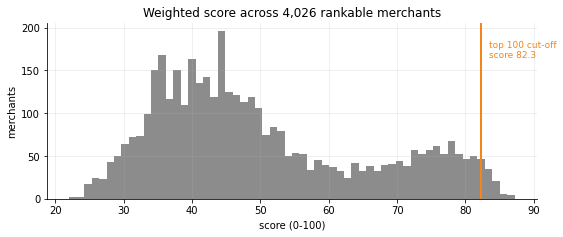

In [8]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#4C78A8", "#F58518", "#8C8C8C"

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(f["score"], bins=60, color=GREY)
cut = top100["score"].min()
ax.axvline(cut, color=ORANGE, linewidth=2)
ax.annotate(f"top 100 cut-off\nscore {cut:.1f}", (cut, ax.get_ylim()[1] * 0.8),
            xytext=(8, 0), textcoords="offset points", color=ORANGE, fontsize=9)
ax.set_title(f"Weighted score across {len(f):,} rankable merchants")
ax.set_xlabel("score (0-100)"); ax.set_ylabel("merchants")
plt.tight_layout(); plt.show()

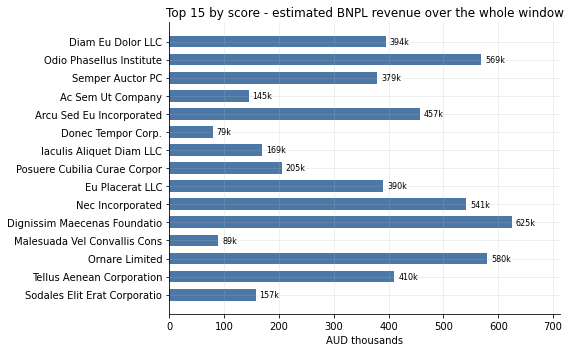

In [9]:
top15 = f.head(15).iloc[::-1]
labels = top15["name"].fillna("(no name)").str.slice(0, 28)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(labels, top15["estimated_bnpl_revenue"] / 1000, color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{v/1000:,.0f}k" for v in top15["estimated_bnpl_revenue"]],
             padding=4, fontsize=8)
ax.set_title("Top 15 by score - estimated BNPL revenue over the whole window")
ax.set_xlabel("AUD thousands")
ax.margins(x=0.14)
plt.tight_layout(); plt.show()

## 6. Is the score doing anything?

Two cheap questions, both worth a slide.

**Does it differ from the obvious baseline?** The brainstorm doc sets that baseline as *rank by
past revenue*. If our top 100 is the same list, the other nine features are decoration.

**Is it stable?** If a ±20% wobble in hand-chosen weights reshuffles the list, the list is an
artefact of those numbers rather than a ranking.

In [10]:
naive_top100 = set(f.nlargest(100, "total_value")["merchant_abn"])
score_top100 = set(top100["merchant_abn"])
overlap = len(naive_top100 & score_top100)

print(f"overlap with a plain GMV ranking : {overlap}/100")
print(f"merchants the score adds         : {100 - overlap}")

rng = np.random.default_rng(0)
churn = []
for _ in range(20):
    jitter = {c: wt * (1 + rng.uniform(-0.2, 0.2)) for c, wt in WEIGHTS.items()}
    total = sum(jitter.values())
    s = sum(ranked[c] * (wt / total) for c, wt in jitter.items())
    shuffled = set(f.assign(_s=s).nlargest(100, "_s")["merchant_abn"])
    churn.append(100 - len(shuffled & score_top100))

print(f"\nweights jittered +/-20%, 20 draws")
print(f"  merchants leaving the top 100: median {int(np.median(churn))}, worst {max(churn)}")

overlap with a plain GMV ranking : 52/100
merchants the score adds         : 48

weights jittered +/-20%, 20 draws
  merchants leaving the top 100: median 4, worst 17


## 7. Where this stands

**Done.** A ranked list of every scorable merchant, built on `01_data_quality_eda`'s feature table
plus customer-base features from `consumers_sa2`, with the weights written down and two checks
against self-deception.

**Deliberately not here**

1. **Fraud** — expected loss should come off the score in dollars. Until the labels are settled,
   this list is "best before risk".
2. **Segments** — the ranks here are global; the top 10 per segment is built in
   `segmentation.ipynb`.
3. **Forecasting** — growth is measured (early 3 months vs recent 3), not projected forward.
4. **Time-split validation** — done since, in `validation_timesplit.ipynb`.

**Assumptions a reader should see**

- The firm earns `GMV × take_rate`, with take rate assumed constant (one value per merchant).
- 396 merchants with no metadata are excluded from ranking, not from the data.
- ABS figures describe a customer's area, not the customer — a prior, not a fact about a person.